# Training a Fashion-MNIST Classifier, and Writing the Optimizer Yourself

[Open in Colab](https://colab.research.google.com/github/ZhuoranYang/sds265-fall26/blob/main/demos/12-neural-optimization/fashion-mnist-optimizers.ipynb)

This notebook goes with Lecture 12. It has two halves.

1. **The PyTorch tutorial, run as written.** Parts 1–4 reproduce the
   [Optimizing Model Parameters](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html) page of PyTorch's
   [Learn the Basics](https://docs.pytorch.org/tutorials/beginner/basics/intro.html) series: a `Dataset`, a `DataLoader`, a small
   network, and the `train_loop` / `test_loop` pair. We then train with the
   tutorial's SGD and with AdamW, changing one line.
2. **The optimizers, implemented by hand.** Parts 5–8 write AdamW and Muon as
   subclasses of `torch.optim.Optimizer`, explain every line, check the
   hand-written AdamW against PyTorch's, and train the same network with
   Muon.

**Compute.** Everything runs on a CPU; no GPU is needed. On a laptop CPU
restricted to two threads, one epoch takes about 5 seconds with SGD or AdamW
and about 17 seconds with Muon, so the notebook's 15 training epochs take a
few minutes. A free Colab CPU runtime is slower than a recent laptop; allow
roughly 5–10 minutes there. If you switch Colab to a GPU runtime (Runtime →
Change runtime type), the code below uses it automatically.

*Tutorial code © PyTorch contributors, BSD-3-Clause; adapted with small
changes noted in the text.*

## 1. Setup

`device` is where tensors live and computation happens: `"cuda"` on a GPU
runtime, `"cpu"` otherwise. Fixing the seed makes the initialization and the
shuffling order reproducible, so that every run below starts from the same
network and sees the batches in the same order.

In [1]:
import math
import time
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import v2
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| CPU threads:", torch.get_num_threads())

device: cpu | CPU threads: 8


## 2. Data: a `Dataset` and two `DataLoader`s

**The dataset.** Fashion-MNIST has 60,000 training and 10,000 test images of
clothing, each $28\times28$ grayscale, in ten classes. `datasets.FashionMNIST`
is a `Dataset`: `training_data[i]` returns the pair $(x_i, y_i)$, and
`len(training_data)` returns $n$. The `transform` runs on one example at a
time; here it turns the stored image into a float tensor of shape
`[1, 28, 28]` with pixel values scaled from $\{0,\ldots,255\}$ to $[0,1]$.
The first run downloads about 30 MB into a `data/` folder.

**The loaders.** A `DataLoader` decides which indices form each batch and
stacks the examples into one tensor. With `shuffle=True` it draws a new
random permutation of $0,\ldots,n-1$ at the start of every epoch and walks
through it in blocks of `batch_size`. This is sampling *without replacement*
within an epoch, as in the lecture.

*Change from the tutorial:* the tutorial's training loader omits
`shuffle=True`, so every epoch visits the same batches in the same order. We
add it. The test loader does not need shuffling, since evaluation does not
depend on the order.

In [2]:
transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
training_data = datasets.FashionMNIST(root="data", train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST(root="data", train=False, download=True, transform=transform)

batch_size = 64
train_dataloader = DataLoader(training_data, batch_size=batch_size, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

x0, y0 = training_data[0]
print("one example: x", tuple(x0.shape), x0.dtype, f"values in [{x0.min():.0f}, {x0.max():.0f}]", "| y =", y0)
print("n =", len(training_data))

one example: x (1, 28, 28) torch.float32 values in [0, 1] | y = 9
n = 60000


**Counting steps.** One pass through `train_dataloader` is one *epoch*,
and each batch it yields gives one optimizer *step*. With $n = 60{,}000$ and
$B = 64$, an epoch has $\lceil n/B\rceil = 938$ steps, because
$60{,}000 = 937 \times 64 + 32$: the last batch holds only 32 images. The
cell checks both numbers and the shapes of one batch.

In [3]:
print("steps per epoch:", len(train_dataloader), "=", math.ceil(len(training_data) / batch_size))
print("last batch size:", len(training_data) - (len(train_dataloader) - 1) * batch_size)

X, y = next(iter(train_dataloader))
print("one batch: X", tuple(X.shape), "| y", tuple(y.shape))
assert len(train_dataloader) == math.ceil(len(training_data) / batch_size) == 938

steps per epoch: 938 = 938
last batch size: 32
one batch: X (64, 1, 28, 28) | y (64,)


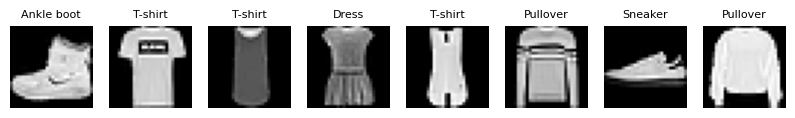

In [4]:
classes = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
fig, axes = plt.subplots(1, 8, figsize=(10, 1.6))
for ax, i in zip(axes, range(8)):
    image, label = training_data[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(classes[label], fontsize=8)
    ax.axis("off")
plt.show()

## 3. The model

The tutorial's network flattens each image to a vector of length 784 and
applies three linear layers with ReLU between them:
$784 \to 512 \to 512 \to 10$. The ten outputs are logits, one per class;
`nn.CrossEntropyLoss` applies the softmax internally.

PyTorch stores the weight of `nn.Linear(d_in, d_out)` as a matrix of shape
`[d_out, d_in]`, plus a bias vector of length `d_out`. The matrices will
matter for Muon, which treats each weight as a matrix and not as a list of
numbers.

In [5]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

for name, p in NeuralNetwork().named_parameters():
    print(f"{name:28s} {str(tuple(p.shape)):12s} {p.numel():>8,d}")
print("total parameters:", f"{sum(p.numel() for p in NeuralNetwork().parameters()):,d}")

linear_relu_stack.0.weight   (512, 784)    401,408
linear_relu_stack.0.bias     (512,)            512
linear_relu_stack.2.weight   (512, 512)    262,144
linear_relu_stack.2.bias     (512,)            512
linear_relu_stack.4.weight   (10, 512)       5,120
linear_relu_stack.4.bias     (10,)              10
total parameters: 669,706


## 4. The training and test loops

These are the tutorial's two functions. Our additions are small: each batch
moves to `device`, and the functions return their averages so we can plot
them.

| line in `train_loop` | what it computes |
|---|---|
| `model.train()` | puts dropout and batch-norm layers in training mode (this model has none, but the call is good practice) |
| `for batch, (X, y) in enumerate(dataloader)` | the minibatch $\mathcal B_t$ |
| `pred = model(X)` | the forward pass; autograd records the operations it will need for the backward pass |
| `loss = loss_fn(pred, y)` | the minibatch loss $L_{\mathcal B_t}(\theta_t)$, one number |
| `loss.backward()` | the gradient $g_t$, **added** into `p.grad` for every parameter `p` |
| `optimizer.step()` | the update $(\theta_{t+1}, s_{t+1}) = \mathcal U(\theta_t, g_t, s_t; \eta)$, reading `p.grad` |
| `optimizer.zero_grad()` | empties every `p.grad`, so the next backward call starts from nothing |

The tutorial zeroes *after* the step; the lecture slides zero *before* the
backward call. The two orders are equivalent, because what matters is that
each `backward()` adds into an empty buffer.

`test_loop` runs the forward pass inside `torch.no_grad()`, which tells
autograd not to record anything: no activations are saved for a backward
pass, so evaluation uses less memory and can never change a gradient.

`run` trains a fresh network from the same seed, so different optimizers
start from identical weights and see the same sequence of shuffled batches.
Its optional `make_scheduler` argument is used only in Section 9.

In [6]:
def train_loop(dataloader, model, loss_fn, optimizer, scheduler=None):
    size = len(dataloader.dataset)
    model.train()
    total = 0.0
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)
        pred = model(X)
        loss = loss_fn(pred, y)

        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        if scheduler is not None:              # our addition: advance eta_t once per step
            scheduler.step()

        total += loss.item()
        if batch % 300 == 0:
            current = batch * dataloader.batch_size + len(X)
            print(f"  loss: {loss.item():>7f}  [{current:>5d}/{size:>5d}]")
    return total / len(dataloader)


def test_loop(dataloader, model, loss_fn):
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"  test accuracy: {100*correct:>0.1f}%, avg loss: {test_loss:>8f}")
    return test_loss, correct


def run(make_optimizer, epochs=5, make_scheduler=None):
    torch.manual_seed(0)                       # same initialization and batch order
    model = NeuralNetwork().to(device)
    optimizer = make_optimizer(model)
    scheduler = make_scheduler(optimizer, epochs * len(train_dataloader)) if make_scheduler else None
    loss_fn = nn.CrossEntropyLoss()
    history = []
    for t in range(epochs):
        start = time.time()
        print(f"Epoch {t+1}")
        train_loop(train_dataloader, model, loss_fn, optimizer, scheduler)
        test_loss, accuracy = test_loop(test_dataloader, model, loss_fn)
        print(f"  {time.time() - start:.1f} s")
        history.append(accuracy)
    return history, model, optimizer

### Run 1: the tutorial's SGD

The tutorial uses plain SGD, $\theta_{t+1} = \theta_t - \eta\, g_t$, with
$\eta = 10^{-3}$. Watch the printed loss: it falls, but slowly, because one
small step size is shared by all 669,706 parameters.

In [7]:
results = {}
results["SGD (tutorial)"], _, sgd = run(lambda m: torch.optim.SGD(m.parameters(), lr=1e-3))
print("SGD keeps state for", len(sgd.state), "parameters")

Epoch 1
  loss: 2.300577  [   64/60000]


  loss: 2.265884  [19264/60000]


  loss: 2.205814  [38464/60000]


  loss: 2.162510  [57664/60000]


  test accuracy: 50.3%, avg loss: 2.162650
  5.5 s
Epoch 2
  loss: 2.177085  [   64/60000]


...

  test accuracy: 63.6%, avg loss: 1.247074
  8.6 s
Epoch 5
  loss: 1.342181  [   64/60000]


  loss: 1.341958  [19264/60000]


  loss: 1.213804  [38464/60000]


  loss: 1.083487  [57664/60000]


  test accuracy: 64.9%, avg loss: 1.076564
  4.9 s
SGD keeps state for 0 parameters


Test accuracy climbs every epoch but ends only in the mid-60s, and the
average test loss is still far above that of a good classifier. The step
size is the bottleneck: $\eta = 10^{-3}$ is safe for the steepest directions
of this loss and therefore slow along all the others. SGD also stored
nothing between steps: its state dictionary is empty.

### Run 2: change one line to AdamW

Same data order, same initialization, same loop, same $\eta = 10^{-3}$. Only
the update rule changes. AdamW divides each coordinate's step by a running
estimate of that coordinate's gradient size, so a single $\eta$ works for
coordinates whose gradients differ by orders of magnitude.

In [8]:
results["AdamW"], model_adamw, adamw = run(lambda m: torch.optim.AdamW(m.parameters(), lr=1e-3))

Epoch 1
  loss: 2.300577  [   64/60000]


  loss: 0.510917  [19264/60000]


  loss: 0.336889  [38464/60000]


  loss: 0.479570  [57664/60000]


  test accuracy: 84.1%, avg loss: 0.432869
  5.9 s
Epoch 2
  loss: 0.412409  [   64/60000]


...

  test accuracy: 88.1%, avg loss: 0.330639
  6.8 s
Epoch 5
  loss: 0.426669  [   64/60000]


  loss: 0.419292  [19264/60000]


  loss: 0.317525  [38464/60000]


  loss: 0.421858  [57664/60000]


  test accuracy: 86.7%, avg loss: 0.368913
  6.3 s


After a single epoch AdamW is already above 80% test accuracy, beyond
where SGD finished after five. Each epoch takes slightly longer, since the
update now touches two state tensors per parameter, but the per-epoch gain
is far larger. Notice also that the test accuracy does not rise every epoch:
with a fixed learning rate and minibatch noise, it fluctuates by a point or
so around its trend.

**What AdamW remembers.** SGD above stored nothing. AdamW stores, for
every parameter tensor `p`, a step counter and two tensors of the same shape
as `p`: `exp_avg` (the first moment $m_t$) and `exp_avg_sq` (the second
moment $v_t$). That is two extra numbers per parameter, the memory cost
discussed in the lecture.

In [9]:
first = next(model_adamw.parameters())
print("state keys for one tensor:", list(adamw.state[first].keys()))
n_params = sum(p.numel() for p in model_adamw.parameters())
n_state = sum(s["exp_avg"].numel() + s["exp_avg_sq"].numel() for s in adamw.state.values())
print(f"parameters: {n_params:,d} | optimizer-state numbers: {n_state:,d} = {n_state / n_params:.0f} per parameter")
print(f"float32 memory: parameters {4 * n_params / 1e6:.1f} MB, gradients {4 * n_params / 1e6:.1f} MB, "
      f"AdamW state {4 * n_state / 1e6:.1f} MB")

state keys for one tensor: ['step', 'exp_avg', 'exp_avg_sq']
parameters: 669,706 | optimizer-state numbers: 1,339,412 = 2 per parameter
float32 memory: parameters 2.7 MB, gradients 2.7 MB, AdamW state 5.4 MB


## 5. What an optimizer object is

Every class in `torch.optim` is built on `torch.optim.Optimizer`, which
provides three things.

- **`self.param_groups`**, a list of dictionaries. Each has a `"params"` entry
  (a list of tensors) and the hyperparameters for those tensors, such as
  `"lr"`. A learning-rate scheduler works by editing `group["lr"]`.
  Constructing `Optimizer(params, defaults)` builds this list and fills
  `defaults` into any group that does not set its own value.
- **`self.state`**, a dictionary keyed by parameter tensor, initially empty
  for every parameter. Each optimizer stores its history there.
- **`zero_grad()`**, which sets every `p.grad` to `None`.

A subclass writes `step()`. We split it in two: a base class whose `step()`
loops over groups and parameters, and an `update` method holding the actual
rule for one tensor. Two details:

- `@torch.no_grad()` is needed because the update itself must not be
  recorded by autograd: changing `p` is bookkeeping outside the model's
  computation.
- `p.grad is None` happens for a parameter that received no gradient (after
  `zero_grad()`, or if it did not affect the loss). Such parameters are
  skipped.

In [10]:
class MyOptimizer(torch.optim.Optimizer):
    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is not None:
                    self.update(p, p.grad, self.state[p], group)

    def update(self, p, g, state, group):
        raise NotImplementedError

## 6. AdamW, line by line

The AdamW update for one tensor, with $g = \nabla_p L$, step count $t$, and
decay $\lambda$:
$$
m_t = \beta_1 m_{t-1} + (1-\beta_1) g, \qquad
v_t = \beta_2 v_{t-1} + (1-\beta_2) g^2, \qquad
\widehat m_t = \frac{m_t}{1-\beta_1^t}, \quad
\widehat v_t = \frac{v_t}{1-\beta_2^t},
$$
$$
p \leftarrow (1-\eta\lambda)\,p \;-\; \eta\, \frac{\widehat m_t}{\sqrt{\widehat v_t} + \varepsilon}.
$$

| code | formula |
|---|---|
| `if not st: st.update(t=0, m=..., v=...)` | on the first call, create $m_0 = v_0 = 0$ with the shape of `p` |
| `st["t"] += 1` | the step count $t$, needed for bias correction |
| `m.mul_(b1).add_(g, alpha=1 - b1)` | $m_t = \beta_1 m_{t-1} + (1-\beta_1) g$ |
| `v.mul_(b2).addcmul_(g, g, value=1 - b2)` | $v_t = \beta_2 v_{t-1} + (1-\beta_2)\, g \odot g$ |
| `m_hat, v_hat = m / (1 - b1**t), v / (1 - b2**t)` | bias corrections |
| `p.mul_(1 - lr * wd)` | decoupled weight decay, $p \leftarrow (1-\eta\lambda) p$ |
| `p.addcdiv_(m_hat, v_hat.sqrt() + eps, value=-lr)` | $p \leftarrow p - \eta\, \widehat m_t / (\sqrt{\widehat v_t}+\varepsilon)$ |

**In-place operations.** Methods ending in an underscore modify the tensor
they are called on: `m.mul_(b1)` multiplies `m` by `b1` and stores the result
in `m`. `add_(g, alpha=c)` adds `c * g`; `addcmul_(a, b, value=c)` adds
`c * a * b`; `addcdiv_(a, b, value=c)` adds `c * a / b`. Updating in place
matters for two reasons: `p` must remain the same tensor object that the
model holds, and no temporary copies of the state are allocated.

In [11]:
class MyAdamW(MyOptimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, wd=0.01):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, wd=wd))

    def update(self, p, g, st, group):
        lr, (b1, b2), eps, wd = (group[k] for k in ("lr", "betas", "eps", "wd"))
        if not st:
            st.update(t=0, m=torch.zeros_like(p), v=torch.zeros_like(p))
        st["t"] += 1
        t, m, v = st["t"], st["m"], st["v"]
        m.mul_(b1).add_(g, alpha=1 - b1)
        v.mul_(b2).addcmul_(g, g, value=1 - b2)
        m_hat, v_hat = m / (1 - b1**t), v / (1 - b2**t)
        p.mul_(1 - lr * wd)
        p.addcdiv_(m_hat, v_hat.sqrt() + eps, value=-lr)

**Check it against PyTorch.** Two copies of the network start from the
same weights. One is trained by `MyAdamW`, the other by `torch.optim.AdamW`
with the same hyperparameters (PyTorch's default weight decay is also 0.01),
on the same 20 batches. If the implementation is right, the weights agree up
to float32 rounding, about $10^{-6}$ or smaller.

In [12]:
torch.manual_seed(0); model_a = NeuralNetwork().to(device)
torch.manual_seed(0); model_b = NeuralNetwork().to(device)
opt_a = MyAdamW(model_a.parameters(), lr=1e-3, wd=0.01)
opt_b = torch.optim.AdamW(model_b.parameters(), lr=1e-3, weight_decay=0.01)
loss_fn = nn.CrossEntropyLoss()
for _, (X, y) in zip(range(20), train_dataloader):
    X, y = X.to(device), y.to(device)
    for model, opt in ((model_a, opt_a), (model_b, opt_b)):
        loss_fn(model(X), y).backward()
        opt.step()
        opt.zero_grad()
gap = max((pa - pb).abs().max().item() for pa, pb in zip(model_a.parameters(), model_b.parameters()))
print(f"largest parameter difference after 20 steps: {gap:.1e}")
assert gap < 1e-5, "MyAdamW disagrees with torch.optim.AdamW"


largest parameter difference after 20 steps: 1.4e-06


The two networks agree to about $10^{-6}$, the size of float32 rounding
after twenty steps of slightly different arithmetic order. So `MyAdamW`
implements exactly the AdamW update, and from here on we can trust it.

## 7. Muon, line by line

### 7a. The update

For a weight matrix $W$ with gradient $G_t$, Muon keeps a momentum matrix and
replaces it by the nearest matrix whose singular values are all one:
$$
M_t = \beta M_{t-1} + G_t, \qquad M_t = U \Sigma V^\top, \qquad
W \leftarrow W - \eta\, U V^\top .
$$
Every singular direction of the step now moves by the same amount. For a
$1\times 1$ "matrix", $UV^\top = \operatorname{sign}(m_t)$, so Muon is sign
descent lifted to matrices.

### 7b. Newton–Schulz: $UV^\top$ without an SVD

An SVD at every step would be slow. Newton–Schulz instead repeats a cheap
polynomial map. Scale $X_0 = M/\lVert M\rVert_F$, so all singular values lie
in $(0,1]$, and iterate
$$
X_{k+1} = a X_k + b\, X_k X_k^\top X_k + c\, (X_k X_k^\top)^2 X_k .
$$
If $X_k = U \Sigma_k V^\top$, then $X_k X_k^\top X_k = U \Sigma_k^3 V^\top$, and
so on: each iteration keeps $U$ and $V$ and applies
$p(\sigma) = a\sigma + b\sigma^3 + c\sigma^5$ to every singular value. The
coefficients $(a, b, c) = (3.4445, -4.7750, 2.0315)$, from Keller Jordan's
implementation, make five applications of $p$ push every singular value that
is not tiny into roughly $[0.7, 1.2]$. That is less exact than an SVD, but it
uses only matrix products, which are fast on any hardware.

The next cell computes the iteration and then watches the singular values of
a random $512 \times 784$ matrix, the shape of our first layer, move toward
one.

In [13]:
def newton_schulz(M, steps=5, a=3.4445, b=-4.7750, c=2.0315):
    X = M / (M.norm() + 1e-7)                 # singular values now in (0, 1]
    for _ in range(steps):
        A = X @ X.T                           # Gram matrix, [rows, rows]
        X = a * X + (b * A + c * A @ A) @ X   # sigma -> p(sigma)
    return X


torch.manual_seed(1)
M = torch.randn(512, 784)
a, b, c = 3.4445, -4.7750, 2.0315
X = M / M.norm()                              # the same iteration, one step at a time
s = torch.linalg.svdvals(X)
print(f"start:  singular values from {s.min():.4f} to {s.max():.4f}")
for k in range(1, 6):
    A = X @ X.T
    X = a * X + (b * A + c * A @ A) @ X
    s = torch.linalg.svdvals(X)
    print(f"step {k}: singular values from {s.min():.4f} to {s.max():.4f}")

U, S, Vh = torch.linalg.svd(M, full_matrices=False)
O = newton_schulz(M)
print("angle between Newton-Schulz output and exact U V^T (cosine):",
      f"{(O * (U @ Vh)).sum() / (O.norm() * (U @ Vh).norm()):.4f}")
s = torch.linalg.svdvals(O)
assert 0.6 < s.min() and s.max() < 1.3

start:  singular values from 0.0089 to 0.0797
step 1: singular values from 0.0307 to 0.2721
step 2: singular values from 0.1056 to 0.8441
step 3: singular values from 0.3581 to 1.2024
step 4: singular values from 0.6818 to 1.2024
step 5: singular values from 0.6818 to 1.1344


angle between Newton-Schulz output and exact U V^T (cosine): 0.9878


The singular values start tiny, because dividing by $\lVert M\rVert_F$
shrinks all of them, and within five iterations every one lies between about
$0.7$ and $1.2$. The output points almost exactly along $UV^\top$ (cosine
close to 1). That is all Muon needs: a step that moves every singular
direction by about the same amount.

### 7c. The `MyMuon` class

| code | meaning |
|---|---|
| `M = st.setdefault("M", torch.zeros_like(p))` | the momentum matrix, created as zeros on the first call: Muon's only state |
| `M.mul_(beta).add_(g)` | $M_t = \beta M_{t-1} + G_t$ |
| `O = newton_schulz(M)` | $O \approx U V^\top$ |
| `scale = max(1, p.size(0) / p.size(1)) ** 0.5` | a larger step for tall matrices (more rows than columns), following Keller Jordan's code; both of our hidden matrices are wide or square, so `scale = 1` here |
| `p.mul_(1 - lr * wd)` | decoupled weight decay, as in AdamW (off by default) |
| `p.add_(O, alpha=-lr * scale)` | $W \leftarrow W - \eta \cdot \text{scale} \cdot O$ |

Muon's step has a fixed size in every direction, so its learning rate is not
comparable to Adam's. The usual default, $\eta = 0.02$, is twenty times
AdamW's $10^{-3}$.

In [14]:
class MyMuon(MyOptimizer):
    def __init__(self, params, lr=0.02, beta=0.95, wd=0.0):
        super().__init__(params, dict(lr=lr, beta=beta, wd=wd))

    def update(self, p, g, st, group):
        M = st.setdefault("M", torch.zeros_like(p))
        M.mul_(group["beta"]).add_(g)
        O = newton_schulz(M)
        scale = max(1, p.size(0) / p.size(1)) ** 0.5
        p.mul_(1 - group["lr"] * group["wd"])
        p.add_(O, alpha=-group["lr"] * scale)

### 7d. Why "Muon + AdamW"

Muon is defined only for **matrices**: $UV^\top$ needs a two-dimensional
weight. A bias is a vector, so Muon has nothing to orthogonalize. The
**output layer** is a matrix, but its rows are the ten class scores, and
standard practice, following Keller Jordan's experiments, keeps it with
AdamW. So a Muon run always uses two optimizers.

- **Muon:** the hidden weight matrices, here `512×784` and `512×512`.
- **AdamW:** the three biases and the `10×512` output weight.

`train_loop` expects one object with `step()` and `zero_grad()`. The small
`Both` class below provides exactly those two methods by calling each
optimizer in turn, so the tutorial's loop runs unchanged. One backward call
fills every `p.grad`; then each optimizer updates only its own tensors.

In [15]:
class Both:
    def __init__(self, *optimizers):
        self.optimizers = optimizers
    def step(self):
        for opt in self.optimizers:
            opt.step()
    def zero_grad(self):
        for opt in self.optimizers:
            opt.zero_grad()


def muon_and_adamw(model):
    head = model.linear_relu_stack[-1].weight
    hidden = [p for p in model.parameters() if p.ndim == 2 and p is not head]
    others = [p for p in model.parameters() if p.ndim < 2 or p is head]
    return Both(MyMuon(hidden, lr=0.02), MyAdamW(others, lr=1e-3))


opt = muon_and_adamw(NeuralNetwork())
for name, o in zip(["Muon", "AdamW"], opt.optimizers):
    shapes = [tuple(p.shape) for p in o.param_groups[0]["params"]]
    print(f"{name:5s} updates {shapes}")

Muon  updates [(512, 784), (512, 512)]
AdamW updates [(512,), (512,), (10, 512), (10,)]


## 8. Run 3: Muon on the hidden matrices

On a CPU each Muon epoch takes about three times as long as an AdamW epoch:
every one of the 938 steps runs five Newton–Schulz iterations on each hidden
matrix. On a GPU those matrix products are cheap.

In [16]:
results["Muon + AdamW"], model_muon, muon = run(muon_and_adamw)
n_state = sum(s["M"].numel() for s in muon.optimizers[0].state.values())
print(f"Muon state: {n_state:,d} numbers, one per hidden-matrix entry")

Epoch 1


  loss: 2.300577  [   64/60000]


  loss: 0.463532  [19264/60000]


  loss: 0.303085  [38464/60000]


  loss: 0.546622  [57664/60000]


...

  test accuracy: 88.8%, avg loss: 0.424726
  19.1 s
Epoch 5
  loss: 0.146081  [   64/60000]


  loss: 0.140648  [19264/60000]


  loss: 0.084474  [38464/60000]


  loss: 0.172313  [57664/60000]


  test accuracy: 88.2%, avg loss: 0.530928
  17.4 s
Muon state: 663,552 numbers, one per hidden-matrix entry


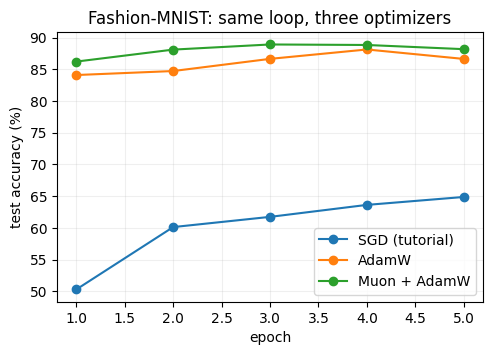

In [17]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for name, history in results.items():
    ax.plot(range(1, len(history) + 1), [100 * a for a in history], marker="o", label=name)
ax.set(xlabel="epoch", ylabel="test accuracy (%)", title="Fashion-MNIST: same loop, three optimizers")
ax.grid(alpha=0.2)
ax.legend()
plt.show()

**Reading the plot.** With the tutorial's settings, SGD is still far
from a good fit after five epochs. AdamW, with the same $\eta$, is far
ahead. Muon on the hidden layers does about as well as AdamW per epoch.
In the last epochs the test *loss* of both can rise while the accuracy
holds: the network grows more confident on the examples it gets wrong, an
early sign of overfitting. These are single runs at one learning rate each,
so they describe each optimizer *at these settings*. A fair comparison tunes
each optimizer's learning rate on a grid (exercise 2) and repeats over
seeds.

## 9. A learning-rate schedule: warmup, then cosine decay

So far $\eta$ was constant. The lecture's schedule, as a function of the
optimizer step $t$ with $T_w$ warmup steps out of $T$ in total, is
$$
\eta_t = \eta_{\max} \times
\begin{cases}
(t+1)/T_w, & t < T_w,\\
\tfrac12\bigl(1 + \cos(\pi\,\tfrac{t - T_w}{T - T_w})\bigr), & t \ge T_w .
\end{cases}
$$
The warmup keeps the first steps small while Adam's $v_t$ is still estimated
from very few gradients; the cosine decay shrinks the steps at the end, so
the iterates settle down from the bouncing that a large $\eta$ causes. `LambdaLR` multiplies the optimizer's base `lr` by `multiplier(t)`
and writes the result into `optimizer.param_groups[0]["lr"]` each time
`scheduler.step()` is called, once per optimizer step.

The next cell plots $\eta_t$ for our run: 5 epochs of 938 steps, so
$T = 4690$, with $T_w = 234$ (5%) and $\eta_{\max} = 10^{-3}$, the same peak
as the constant-rate AdamW run.

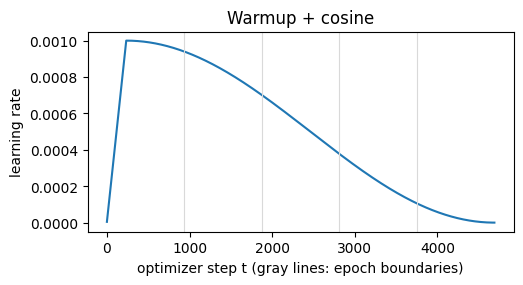

first step 4.27e-06, peak 1.00e-03 at step 233, last step 1.24e-10


In [18]:
def warmup_cosine(optimizer, total_steps, warmup_frac=0.05):
    warmup_steps = int(warmup_frac * total_steps)

    def multiplier(t):                    # t counts optimizer steps
        if t < warmup_steps:
            return (t + 1) / warmup_steps
        progress = (t - warmup_steps) / (total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * progress))

    return torch.optim.lr_scheduler.LambdaLR(optimizer, multiplier)


# Trace the schedule on a throwaway optimizer, without training.
probe = torch.optim.AdamW([torch.zeros(1, requires_grad=True)], lr=1e-3)
sched = warmup_cosine(probe, total_steps=5 * len(train_dataloader))
lrs = []
for _ in range(5 * len(train_dataloader)):
    lrs.append(probe.param_groups[0]["lr"])
    probe.step(); sched.step()

fig, ax = plt.subplots(figsize=(5.5, 2.6))
ax.plot(lrs)
for e in range(1, 5):
    ax.axvline(e * len(train_dataloader), color="0.85", lw=0.8)
ax.set(xlabel="optimizer step t (gray lines: epoch boundaries)", ylabel="learning rate", title="Warmup + cosine")
plt.show()
print(f"first step {lrs[0]:.2e}, peak {max(lrs):.2e} at step {lrs.index(max(lrs))}, last step {lrs[-1]:.2e}")
assert abs(max(lrs) - 1e-3) < 1e-12 and lrs[-1] < 1e-6

The rate climbs linearly to $10^{-3}$ in the first quarter of epoch 1,
then follows half a cosine down to almost zero at the last step. Now train
AdamW with this schedule, the same peak rate, and the same five epochs.

Epoch 1
  loss: 2.300577  [   64/60000]


  loss: 0.521323  [19264/60000]


  loss: 0.313578  [38464/60000]


  loss: 0.512994  [57664/60000]


  test accuracy: 84.1%, avg loss: 0.433927
  6.1 s
Epoch 2
  loss: 0.423877  [   64/60000]


...

  test accuracy: 88.7%, avg loss: 0.314989
  5.7 s
Epoch 5
  loss: 0.346619  [   64/60000]


  loss: 0.317821  [19264/60000]


  loss: 0.295362  [38464/60000]


  loss: 0.293251  [57664/60000]


  test accuracy: 88.8%, avg loss: 0.311256
  5.7 s


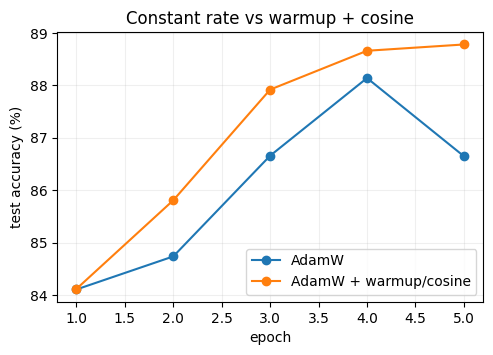

AdamW                  final test accuracy 86.7%
AdamW + warmup/cosine  final test accuracy 88.8%


In [19]:
results["AdamW + warmup/cosine"], _, _ = run(
    lambda m: torch.optim.AdamW(m.parameters(), lr=1e-3), make_scheduler=warmup_cosine)

fig, ax = plt.subplots(figsize=(5.5, 3.5))
for name in ["AdamW", "AdamW + warmup/cosine"]:
    history = results[name]
    ax.plot(range(1, len(history) + 1), [100 * a for a in history], marker="o", label=name)
ax.set(xlabel="epoch", ylabel="test accuracy (%)", title="Constant rate vs warmup + cosine")
ax.grid(alpha=0.2); ax.legend()
plt.show()
for name in ["AdamW", "AdamW + warmup/cosine"]:
    print(f"{name:22s} final test accuracy {100 * results[name][-1]:.1f}%")

The scheduled run ends at about 88.8% test accuracy with test loss
0.31, against 86.7% and 0.37 for the constant rate. Epoch 1 is nearly the
same for both, because the warmup lasts only a quarter of an epoch. The gap
opens in the last two epochs, when the cosine has shrunk $\eta_t$ to a few
percent of its peak: the constant-rate run keeps bouncing (its accuracy even
drops in epoch 5), while the scheduled run settles. Same optimizer, same peak
rate, same number of steps: the schedule alone is worth about two points
here.

## 10. Try it yourself

1. Remove `shuffle=True` from the training loader and rerun AdamW. Does the
   test accuracy after five epochs change?
2. Run SGD with `lr=1e-1` and `lr=1e-2`. How much of the gap to AdamW is due
   only to the step size?
3. Set `batch_size = 256` and rebuild the loaders. How many optimizer steps
   does an epoch take now, and how does the time per epoch change?
4. Train with `MyAdamW` in place of `torch.optim.AdamW` in `run`. The curve
   should match Run 2.
5. In `newton_schulz`, try `steps=2` and `steps=10`. How do the singular
   values and Muon's accuracy change?
6. In `warmup_cosine`, set `warmup_frac=0` and raise the peak to `lr=3e-3`.
   Predict first: does the run without warmup still train?